# UTKFace × Face Symmetry Lab（symmetry-3d/1.0.0）

顔の左右差だけを測る。年齢・性別・人種は **UTKFace のファイル名注釈**
（`age_gender_race_datetime.jpg`）をそのまま使い、推論モデルは持たない。

出力（`/content`）:

| ファイル | 内容 |
|---|---|
| `utkface_symmetry3d_records.csv` | 測定できた 18〜75 歳の**個票**（画像は含まない） |
| `utkface_symmetry3d_group_means.csv` | 年齢 / 年齢帯 / 性別 / 人種ごとの平均 |
| `utkface_symmetry3d_measurement_stats.csv` | 全体の測定統計 |
| `utkface_symmetry3d_summary.json` | 実行条件・件数・統計・警告 |

探索的な記述統計であり、正常値・目標値・人物評価ではない。


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
# -*- coding: utf-8 -*-
ACCEPT_UTKFACE_NONCOMMERCIAL_RESEARCH_TERMS = True
assert ACCEPT_UTKFACE_NONCOMMERCIAL_RESEARCH_TERMS, (
    'UTKFace公式ページの非商用研究限定条件と所属機関のルールを確認してください。'
)

import subprocess
import sys

PACKAGES = [
    'kagglehub==1.0.2',
    'opencv-contrib-python==5.0.0.93',  # 不変条件9: contrib 1本に限定（mediapipe の依存）
    'mediapipe==0.10.35',
    'pillow==12.3.0',
]

# 1) uv 自体を入れる（これ自体は pip、以降を uv で高速化）
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', 'uv'], check=True)

# 2) opencv の重複ディストリビューションを uv で除去（不変条件9）
subprocess.run(
    [sys.executable, '-m', 'uv', 'pip', 'uninstall', '--system',
     'opencv-python', 'opencv-python-headless',
     'opencv-contrib-python', 'opencv-contrib-python-headless'],
    check=False, capture_output=True, text=True,
)

# 3) 固定版を uv で一括インストール（NumPy は Colab 標準を維持＝上書きしない）
subprocess.run(
    [sys.executable, '-m', 'uv', 'pip', 'install', '--system', '--quiet', *PACKAGES],
    check=True,
)
print('依存関係を uv で準備しました。')

依存関係を uv で準備しました。


In [2]:
import hashlib
from pathlib import Path
from urllib.request import urlopen

MODEL_VERSION = 'mediapipe-face-landmarker/float16-1'
MODEL_URL = (
    'https://storage.googleapis.com/mediapipe-models/'
    'face_landmarker/face_landmarker/float16/1/face_landmarker.task'
)
MODEL_SIZE_BYTES = 3_758_596
MODEL_SHA256 = (
    '64184e229b263107bc2b804c6625db134'
    '1ff2bb731874b0bcc2fe6544e0bc9ff'
)
MODEL_DIR = Path('/content/face-symmetry-models')
MODEL_PATH = MODEL_DIR / 'face_landmarker.task'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def model_is_valid(path: Path) -> bool:
    return (
        path.is_file()
        and path.stat().st_size == MODEL_SIZE_BYTES
        and sha256_file(path) == MODEL_SHA256
    )

if not model_is_valid(MODEL_PATH):
    temporary_path = MODEL_PATH.with_suffix('.task.part')
    digest = hashlib.sha256()
    received = 0
    with urlopen(MODEL_URL, timeout=60) as response:
        with temporary_path.open('wb') as handle:
            while chunk := response.read(1024 * 1024):
                received += len(chunk)
                digest.update(chunk)
                handle.write(chunk)
    assert received == MODEL_SIZE_BYTES, (
        f'model size mismatch: {received} != {MODEL_SIZE_BYTES}'
    )
    assert digest.hexdigest() == MODEL_SHA256, 'model SHA-256 mismatch'
    temporary_path.replace(MODEL_PATH)

assert model_is_valid(MODEL_PATH), '固定モデルを検証できませんでした。'
print(f'model: {MODEL_VERSION}')
print(f'SHA-256: {MODEL_SHA256}')

# 年齢・性別の推論モデルは使わない。UTKFace はファイル名に
# age_gender_race_datetime を持つので、注釈をそのまま使う（推定しない）。

model: mediapipe-face-landmarker/float16-1
SHA-256: 64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff


In [3]:
from collections import Counter

import kagglehub

UTKFACE_OFFICIAL_PAGE_URL = 'https://susanqq.github.io/UTKFace/'
KAGGLE_MIRRORS = (
    'moritzm00/utkface-cropped/versions/1',
    'jangedoo/utkface-new/versions/1',
)
download_errors = []
dataset_root = None
DATASET_MIRROR_HANDLE = None

for mirror_handle in KAGGLE_MIRRORS:
    try:
        dataset_root = Path(
            kagglehub.dataset_download(mirror_handle)
        )
        DATASET_MIRROR_HANDLE = mirror_handle
        break
    except Exception as error:
        download_errors.append(
            f'{mirror_handle}: {type(error).__name__}: {error}'
        )

if dataset_root is None or DATASET_MIRROR_HANDLE is None:
    details = '\n'.join(download_errors)
    raise RuntimeError(
        '公開KaggleミラーからUTKFaceを取得できませんでした。'
        '通常は認証不要ですが、Kaggle側が認証を要求する場合はColabの'
        'SecretsへKAGGLE_API_TOKENを登録して再実行してください。\n'
        f'{details}'
    )

all_images = [
    path
    for path in dataset_root.rglob('*')
    if path.is_file() and path.suffix.lower() in {'.jpg', '.jpeg'}
]
images_per_directory = Counter(path.parent for path in all_images)
assert images_per_directory, '取得データ内にJPEG画像がありません。'
DATASET_DIR, _ = images_per_directory.most_common(1)[0]
image_paths = sorted(
    path for path in all_images if path.parent == DATASET_DIR
)
assert 20_000 <= len(image_paths) <= 25_000, (
    'UTKFace Aligned & Cropped本体を特定できませんでした: '
    f'{len(image_paths):,}枚 ({DATASET_DIR})'
)

inventory_digest = hashlib.sha256()
for path in image_paths:
    record = f'{path.name}\0{path.stat().st_size}\n'
    inventory_digest.update(record.encode('utf-8'))
DATASET_INVENTORY_SHA256 = inventory_digest.hexdigest()
DATASET_MIRROR_URL = (
    'https://www.kaggle.com/datasets/'
    + DATASET_MIRROR_HANDLE.split('/versions/')[0]
)

print(f'mirror: {DATASET_MIRROR_HANDLE}')
print(f'dataset: {DATASET_DIR}')
print(f'inventory SHA-256: {DATASET_INVENTORY_SHA256}')
print(f'images: {len(image_paths):,}')
print(f'例: {image_paths[0].name}  （age_gender_race_datetime）')

100%|██████████| 116M/116M [00:06<00:00, 19.1MB/s]

Extracting files...


mirror: moritzm00/utkface-cropped/versions/1
dataset: /root/.cache/kagglehub/datasets/moritzm00/utkface-cropped/versions/1/UTKFace
inventory SHA-256: 561a2899851724676189e46898c81a0835913bd4e5c4ec63a6c00a76efaa6cb0
images: 23,708
例: 100_0_0_20170112213500903.jpg.chip.jpg  （age_gender_race_datetime）


In [4]:
import os

MIN_AGE = 18
MAX_AGE = 75
MAX_ABS_YAW_DEG = 15.0    # アプリの厳格ゲート内側と一致
MAX_ABS_PITCH_DEG = 15.0
MAX_ABS_ROLL_DEG = 25.0
MAX_IMAGES = None          # 動作確認だけなら 100
RANDOM_SEED = 20260810
BOOTSTRAP_SAMPLES = 2_000
PROGRESS_EVERY = 500
MIN_GROUP_FOR_CI = 8       # これ未満の群では bootstrap CI を出さない（NaN を出さない）

# 年齢ゲートはデータセット注釈（ファイル名の実年齢）で判定する。モデル推定は行わない。
# 高速化パラメータ
USE_MULTIPROCESSING = True
N_WORKERS = min(os.cpu_count() or 2, 4)
CHUNK = 32
print({'workers': N_WORKERS, 'age_range': [MIN_AGE, MAX_AGE],
       'age_source': 'dataset filename annotation'})

{'workers': 2, 'age_range': [18, 75], 'age_source': 'dataset filename annotation'}


In [5]:
%%writefile /content/fsl_symmetry.py
"""Face Symmetry Lab と同一の 3D 計算（symmetry-3d/1.0.0）を行う並列ワーカ本体。

年齢・性別はモデルで推定しない。UTKFace のファイル名が持つデータセット注釈
（age_gender_race_datetime）をそのまま使うため、本 notebook は左右差だけを測る。
"""

from __future__ import annotations

import math
import re
from pathlib import Path

import numpy as np

# ---- 指標定数：configs/metrics/symmetry-3d-v1.json と同一 ----
METRIC_VERSION = "symmetry-3d/1.0.0"
LANDMARK_MAP_VERSION = "mediapipe-478-mirror/1.0.0"
LANDMARK_COUNT = 478
PART_NAMES = ("contour", "eyes", "nose", "mouth")
LEFT_EYE_CORNERS = (33, 133)
RIGHT_EYE_CORNERS = (263, 362)
PART_PAIRS = {
    "contour": (
        (21, 251), (54, 284), (58, 288), (67, 297), (93, 323),
        (103, 332), (109, 338), (127, 356), (132, 361), (136, 365),
        (148, 377), (149, 378), (150, 379), (162, 389), (172, 397),
        (176, 400), (234, 454),
    ),
    "eyes": (
        (7, 249), (33, 263), (46, 276), (52, 282), (53, 283),
        (55, 285), (63, 293), (65, 295), (66, 296), (70, 300),
        (105, 334), (107, 336), (133, 362), (144, 373),
        (145, 374), (153, 380), (154, 381), (155, 382),
        (157, 384), (158, 385), (159, 386), (160, 387),
        (161, 388), (163, 390), (173, 398), (246, 466),
    ),
    "nose": (
        (45, 275), (48, 278), (64, 294), (97, 326), (98, 327),
        (115, 344), (220, 440),
    ),
    "mouth": (
        (37, 267), (39, 269), (74, 270), (76, 291), (78, 306),
        (81, 311), (82, 312), (84, 314), (87, 317), (88, 319),
        (90, 321), (178, 403), (181, 405),
    ),
}
MIN_PAIRS = {"contour": 8, "eyes": 13, "nose": 3, "mouth": 6}
OVERALL_MIN_PAIRS = sum(MIN_PAIRS.values())
POOLED_PAIRS = tuple(pair for name in PART_NAMES for pair in PART_PAIRS[name])
SERIES = (*PART_NAMES, "overall")

# ---- 表示スケール：domain/score_scale.py と同一 ----
DISPLAY_SCALE_VERSION = "display-scale/1.0.0"
DISTANCE_AT_FULL_SCORE = 0.010
DISTANCE_AT_ZERO_SCORE = 0.050
MIN_EYE_DISTANCE = 1e-9

# ---- UTKFace のファイル名注釈：age_gender_race_datetime.jpg ----
UTKFACE_NAME_PATTERN = re.compile(r"^(\d{1,3})_([01])_([0-4])_\d+")
GENDER_LABELS = {0: "male", 1: "female"}
RACE_LABELS = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}

# ---- 事前計算（全画像で不変。ホットループから追い出す）----
_USED = sorted({index for pair in POOLED_PAIRS for index in pair})
_USED_ARR = np.asarray(_USED, dtype=np.int64)
_POSITION = {landmark: order for order, landmark in enumerate(_USED)}
_SWAP = np.arange(len(_USED))
for _left, _right in POOLED_PAIRS:
    _SWAP[_POSITION[_left]], _SWAP[_POSITION[_right]] = _POSITION[_right], _POSITION[_left]
_PART_ROWS = {
    name: np.asarray(
        [_POSITION[index] for pair in PART_PAIRS[name] for index in pair], dtype=np.int64
    )
    for name in PART_NAMES
}
_LEFT2 = list(LEFT_EYE_CORNERS)
_RIGHT2 = list(RIGHT_EYE_CORNERS)

# ---- ゲート/モデル（init_worker で設定）----
MODEL_PATH = ""
MAX_ABS_YAW_DEG = 15.0
MAX_ABS_PITCH_DEG = 15.0
MAX_ABS_ROLL_DEG = 25.0
_LANDMARKER = None


def parse_utkface_name(name: str):
    """`25_0_2_20170116174525125.jpg.chip.jpg` → 注釈 dict。読めなければ None。

    UTKFace には race 欄が欠けた壊れたファイル名が数件ある。推測で埋めず、
    読めないものは呼び出し側が母集団から外す（不変条件 11 と同じ姿勢）。
    """
    match = UTKFACE_NAME_PATTERN.match(name)
    if match is None:
        return None
    age, gender_code, race_code = (int(group) for group in match.groups())
    return {
        "age": age,
        "gender_code": gender_code,
        "gender": GENDER_LABELS[gender_code],
        "race_code": race_code,
        "race": RACE_LABELS[race_code],
    }


def normalize_landmarks_3d(points: np.ndarray) -> np.ndarray:
    """geometry.normalize_landmarks_3d と同一。スケールは 3D の両眼間距離。"""
    array = np.asarray(points, dtype=np.float64)
    left2 = array[_LEFT2, :2].mean(axis=0)
    right2 = array[_RIGHT2, :2].mean(axis=0)
    delta = right2 - left2
    distance2d = float(np.hypot(delta[0], delta[1]))
    if distance2d <= MIN_EYE_DISTANCE:
        raise ValueError("eye distance too small")
    cosine = float(delta[0]) / distance2d
    sine = -float(delta[1]) / distance2d
    rotation = np.array([[cosine, -sine], [sine, cosine]], dtype=np.float64)
    center = (left2 + right2) / 2.0
    left3 = array[_LEFT2].mean(axis=0)
    right3 = array[_RIGHT2].mean(axis=0)
    scale = float(np.linalg.norm(right3 - left3))
    if scale <= MIN_EYE_DISTANCE:
        raise ValueError("eye distance too small")
    plane = ((array[:, :2] - center) @ rotation.T) / scale
    depth = (array[:, 2] - float(left3[2] + right3[2]) / 2.0) / scale
    return np.column_stack([plane, depth])


def axis_split(residual: np.ndarray) -> dict:
    """symmetry_3d.axis_split と同一。distance² = plane² + depth² が恒等に成り立つ。"""
    return {
        "distance": float(np.sqrt((residual**2).sum(axis=1).mean())),
        "plane": float(np.sqrt((residual[:, :2] ** 2).sum(axis=1).mean())),
        "depth": float(np.sqrt((residual[:, 2] ** 2).mean())),
    }


def compute_scores_3d(points: np.ndarray) -> dict:
    """478 点そろった顔 1 つ分。compute_symmetry_3d + equal_weight_distance と同一。"""
    normalized = normalize_landmarks_3d(points)
    original = normalized[_USED_ARR]
    mirrored = original.copy()
    mirrored[:, 0] *= -1.0
    mirrored = mirrored[_SWAP]
    centred = original - original.mean(axis=0)
    mirrored_centred = mirrored - mirrored.mean(axis=0)
    left_vectors, _, right_vectors = np.linalg.svd(mirrored_centred.T @ centred)
    rotation = left_vectors @ right_vectors
    if np.linalg.det(rotation) < 0:
        left_vectors[:, -1] *= -1.0
        rotation = left_vectors @ right_vectors
    residual = centred - (mirrored_centred @ rotation)

    result = {name: axis_split(residual[_PART_ROWS[name]]) for name in PART_NAMES}
    result["overall"] = axis_split(residual)
    result["s_3d"] = math.sqrt(
        sum(result[name]["distance"] ** 2 for name in PART_NAMES) / len(PART_NAMES)
    )
    return result


def symmetry_percent(distance):
    """ui.readings.symmetry_percent と同一。"""
    if distance is None or not math.isfinite(distance):
        return None
    return min(100.0, max(0.0, (1.0 - distance) * 100.0))


def score_points(distance):
    """s_3d を 0〜100 点へ。score_scale.score_points と同一。"""
    if distance is None or not math.isfinite(distance):
        return None
    span = DISTANCE_AT_ZERO_SCORE - DISTANCE_AT_FULL_SCORE
    points = 100.0 * (DISTANCE_AT_ZERO_SCORE - distance) / span
    return min(100.0, max(0.0, points))


def pose_degrees(matrix: np.ndarray):
    """pose.pose_from_matrix と同一の yaw/pitch/roll（度）。"""
    linear = np.asarray(matrix, dtype=np.float64)[:3, :3]
    left, singular_values, right = np.linalg.svd(linear)
    if singular_values.min() <= 1e-7:
        raise ValueError("pose matrix is degenerate")
    rotation = left @ right
    if np.linalg.det(rotation) < 0:
        raise ValueError("pose matrix contains reflection")
    sin_pitch = float(np.clip(-rotation[1, 2], -1.0, 1.0))
    pitch = math.asin(sin_pitch)
    cos_pitch = math.sqrt(max(0.0, 1.0 - sin_pitch * sin_pitch))
    if cos_pitch > 1e-7:
        yaw = math.atan2(float(rotation[0, 2]), float(rotation[2, 2]))
        roll = math.atan2(float(rotation[1, 0]), float(rotation[1, 1]))
    else:
        yaw = math.atan2(-float(rotation[2, 0]), float(rotation[0, 0]))
        roll = 0.0
    return tuple(math.degrees(value) for value in (yaw, pitch, roll))


def init_worker(model_path: str, gates: tuple):
    global MODEL_PATH, MAX_ABS_YAW_DEG, MAX_ABS_PITCH_DEG, MAX_ABS_ROLL_DEG
    MODEL_PATH = model_path
    MAX_ABS_YAW_DEG, MAX_ABS_PITCH_DEG, MAX_ABS_ROLL_DEG = gates


def _get_landmarker():
    global _LANDMARKER
    if _LANDMARKER is None:
        import mediapipe as mp
        from mediapipe.tasks.python import BaseOptions
        from mediapipe.tasks.python.vision import (
            FaceLandmarker, FaceLandmarkerOptions, RunningMode,
        )
        options = FaceLandmarkerOptions(
            base_options=BaseOptions(
                model_asset_path=str(MODEL_PATH),
                delegate=BaseOptions.Delegate.CPU,
            ),
            running_mode=RunningMode.IMAGE,
            num_faces=2,
            output_facial_transformation_matrixes=True,
        )
        _LANDMARKER = FaceLandmarker.create_from_options(options)
    return _LANDMARKER


def analyze_one_path(path_str: str):
    """1 枚を解析して ('ok', 測定値) か ('除外理由', None) を返す。"""
    import mediapipe as mp
    from PIL import Image, ImageOps

    path = Path(path_str)
    try:
        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
            rgb = np.asarray(image, dtype=np.uint8)
    except Exception:
        return ("image_decode_failed", None)

    landmarker = _get_landmarker()
    try:
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        detection = landmarker.detect(mp_image)
    except Exception:
        return ("landmark_detection_error", None)

    faces = list(detection.face_landmarks or [])
    if len(faces) == 0:
        return ("no_face", None)
    if len(faces) > 1:
        return ("multiple_faces", None)
    if len(faces[0]) != LANDMARK_COUNT:
        return ("unexpected_landmark_count", None)

    matrices = list(detection.facial_transformation_matrixes or [])
    if len(matrices) != 1:
        return ("pose_missing", None)
    try:
        yaw, pitch, roll = pose_degrees(np.asarray(matrices[0]))
    except (ValueError, np.linalg.LinAlgError):
        return ("pose_missing", None)
    if (
        abs(yaw) > MAX_ABS_YAW_DEG
        or abs(pitch) > MAX_ABS_PITCH_DEG
        or abs(roll) > MAX_ABS_ROLL_DEG
    ):
        return ("pose_outside_limits", None)

    height, width = rgb.shape[:2]
    points = np.asarray(
        [(p.x * width, p.y * height, p.z * width) for p in faces[0]], dtype=np.float64
    )
    if not np.isfinite(points).all():
        return ("symmetry_error", None)
    try:
        scores = compute_scores_3d(points)
    except (ValueError, np.linalg.LinAlgError):
        return ("symmetry_error", None)

    record = {
        "image_width": int(width),
        "image_height": int(height),
        "yaw_deg": float(yaw),
        "pitch_deg": float(pitch),
        "roll_deg": float(roll),
        "s3d_distance": float(scores["s_3d"]),
        "score_points": score_points(scores["s_3d"]),
    }
    for name in SERIES:
        record[f"distance_{name}"] = scores[name]["distance"]
        record[f"plane_{name}"] = scores[name]["plane"]
        record[f"depth_{name}"] = scores[name]["depth"]
        record[f"symmetry_percent_{name}"] = symmetry_percent(scores[name]["distance"])
    if any(value is None or not math.isfinite(value) for value in record.values()):
        # 欠測・NaN・Inf を結果へ流さない（不変条件 11）。0 で埋めない。
        return ("non_finite_score", None)
    return ("ok", record)

Writing /content/fsl_symmetry.py


In [6]:
import sys
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp_ctx

import numpy as np

sys.path.insert(0, "/content")   # spawn した子プロセスが fsl_symmetry を import できるように
import fsl_symmetry

# --- 母集団：ファイル名の注釈（age_gender_race_datetime）で 18〜75 歳へ絞る ---
# 実年齢・性別・人種はデータセット注釈として与えられているので、ここでは推定しない。
inventory_exclusions = Counter()
candidates = []                      # [(Path, 注釈dict), ...]
for path in image_paths:             # 前セルで作成済み
    annotation = fsl_symmetry.parse_utkface_name(path.name)
    if annotation is None:
        inventory_exclusions["unparsable_filename"] += 1
        continue
    if not (MIN_AGE <= annotation["age"] <= MAX_AGE):
        inventory_exclusions["age_outside_range"] += 1
        continue
    candidates.append((path, annotation))

assert candidates, "18〜75歳の注釈を持つ画像が 0 件でした。"

# 長い測定へ入る前に、注釈の読み取りが壊れていないことを目視できるようにする
print(f"candidates: {len(candidates):,} / {len(image_paths):,}")
print("gender:", dict(Counter(a["gender"] for _, a in candidates)))
print("race  :", dict(Counter(a["race"] for _, a in candidates)))
print("inventory exclusions:", dict(inventory_exclusions))

if MAX_IMAGES is None or MAX_IMAGES >= len(candidates):
    selected = tuple(candidates)
else:
    generator = np.random.default_rng(RANDOM_SEED)
    indices = sorted(
        int(index)
        for index in generator.choice(len(candidates), size=MAX_IMAGES, replace=False)
    )
    selected = tuple(candidates[index] for index in indices)

path_strings = [str(path) for path, _ in selected]
gates = (MAX_ABS_YAW_DEG, MAX_ABS_PITCH_DEG, MAX_ABS_ROLL_DEG)

records = []                         # 1 要素 = 1 画像の個票（画像そのものは持たない）
analysis_exclusions = Counter()


def _consume(image_id, path, annotation, status, payload):
    """測定できた画像だけを個票へ積む。失敗は理由別に数えるだけで止めない（不変条件12）。"""
    if status != "ok":
        analysis_exclusions[status] += 1
        return
    records.append(
        {"image_id": image_id, "filename": path.name, **annotation, **payload}
    )


if USE_MULTIPROCESSING and N_WORKERS > 1:
    context = mp_ctx.get_context("spawn")   # MediaPipe を fork しない
    with ProcessPoolExecutor(
        max_workers=N_WORKERS,
        mp_context=context,
        initializer=fsl_symmetry.init_worker,
        initargs=(str(MODEL_PATH), gates),
    ) as executor:
        outcomes = executor.map(
            fsl_symmetry.analyze_one_path, path_strings, chunksize=CHUNK
        )
        for image_id, ((path, annotation), (status, payload)) in enumerate(
            zip(selected, outcomes), start=1
        ):
            _consume(image_id, path, annotation, status, payload)
            if image_id % PROGRESS_EVERY == 0 or image_id == len(selected):
                print(f"processed {image_id:,}/{len(selected):,} (valid={len(records):,})")
else:
    fsl_symmetry.init_worker(str(MODEL_PATH), gates)
    try:
        for image_id, (path, annotation) in enumerate(selected, start=1):
            status, payload = fsl_symmetry.analyze_one_path(str(path))
            _consume(image_id, path, annotation, status, payload)
            if image_id % PROGRESS_EVERY == 0 or image_id == len(selected):
                print(f"processed {image_id:,}/{len(selected):,} (valid={len(records):,})")
    finally:
        if fsl_symmetry._LANDMARKER is not None:
            fsl_symmetry._LANDMARKER.close()

valid_count = len(records)
assert valid_count > 0, "採用条件（注釈18〜75歳＋単一顔＋姿勢ゲート）を満たす画像が0件でした。"
print(f"valid: {valid_count:,}/{len(selected):,}")
print(f"inventory exclusions: {dict(inventory_exclusions)}")
print(f"analysis exclusions : {dict(analysis_exclusions)}")

candidates: 18,621 / 23,708
gender: {'male': 10008, 'female': 8613}
race  : {'White': 7625, 'Black': 4164, 'Asian': 2301, 'Indian': 3355, 'Others': 1176}
inventory exclusions: {'age_outside_range': 5084, 'unparsable_filename': 3}
processed 500/18,621 (valid=389)
processed 1,000/18,621 (valid=718)
processed 1,500/18,621 (valid=1,060)
processed 2,000/18,621 (valid=1,388)
processed 2,500/18,621 (valid=1,720)
processed 3,000/18,621 (valid=2,095)
processed 3,500/18,621 (valid=2,408)
processed 4,000/18,621 (valid=2,779)
processed 4,500/18,621 (valid=3,142)
processed 5,000/18,621 (valid=3,456)
processed 5,500/18,621 (valid=3,764)
processed 6,000/18,621 (valid=4,137)
processed 6,500/18,621 (valid=4,495)
processed 7,000/18,621 (valid=4,863)
processed 7,500/18,621 (valid=5,261)
processed 8,000/18,621 (valid=5,657)
processed 8,500/18,621 (valid=6,040)
processed 9,000/18,621 (valid=6,436)
processed 9,500/18,621 (valid=6,828)
processed 10,000/18,621 (valid=7,244)
processed 10,500/18,621 (valid=7,65

個票 14,754 行を書き出しました: /content/utkface_symmetry3d_records.csv


,image_id,filename,age,gender_code,gender,race_code,race,image_width,image_height,yaw_deg,...,symmetry_percent_nose,distance_mouth,plane_mouth,depth_mouth,symmetry_percent_mouth,distance_overall,plane_overall,depth_overall,symmetry_percent_overall,age_band
0,1,18_0_0_20170103201308008.jpg.chip.jpg,18,0,male,0,White,200,200,2.251943,...,97.480007,0.031795,0.030197,0.009953,96.820509,0.021160,0.020383,0.005680,97.883985,18-24
1,2,18_0_0_20170103201519511.jpg.chip.jpg,18,0,male,0,White,200,200,11.251299,...,94.103957,0.035582,0.032776,0.013849,96.441830,0.061745,0.052540,0.032434,93.825509,18-24
2,3,18_0_0_20170105183259439.jpg.chip.jpg,18,0,male,0,White,200,200,-2.496007,...,98.223098,0.026542,0.024932,0.009104,97.345810,0.019113,0.017853,0.006826,98.088679,18-24
3,4,18_0_0_20170110223927225.jpg.chip.jpg,18,0,male,0,White,200,200,-1.592140,...,98.143712,0.036759,0.034463,0.012787,96.324086,0.021769,0.020718,0.006682,97.823103,18-24
4,5,18_0_0_20170110231228322.jpg.chip.jpg,18,0,male,0,White,200,200,-0.029674,...,99.160816,0.030918,0.029599,0.008937,96.908166,0.020412,0.019879,0.004633,97.958840,18-24



=== 全体平均（UTKFace 探索値・目標値ではない）===
■ 全体のスコア : 39.71 点 / 100 (95%CI 39.26–40.18)
■ 全体の対称度 : 96.15 % (95%CI 96.12–96.18)
   輪郭の対称度: 95.05 %
   目の対称度: 97.04 %
   鼻の対称度: 97.02 %
   口の対称度: 96.40 %
採用: 14,754/18,621 (79.2%)

=== 年齢（1歳きざみ・データセット注釈） ごとの平均（全体のスコア: 点/100）===


,group,count,mean_score_points,standard_deviation,median_score_points,mean_ci95_low,mean_ci95_high,mean_symmetry_percent_overall,mean_s3d_distance
0,18,205,41.886,29.406,46.406,37.778,45.891,96.306,0.037
1,19,77,49.344,28.677,58.629,43.075,55.555,96.751,0.033
2,20,205,41.883,29.214,47.339,37.863,45.715,96.281,0.037
3,21,223,38.953,29.044,37.274,34.965,42.613,96.244,0.038
4,22,268,44.719,28.870,52.664,41.291,48.034,96.495,0.035
5,23,268,41.070,29.634,45.137,37.445,44.665,96.216,0.038
6,24,588,38.780,29.570,44.058,36.441,41.124,96.114,0.039
7,25,511,42.448,28.593,47.657,40.043,44.966,96.409,0.036
8,26,1486,38.354,28.489,42.161,36.902,39.854,96.078,0.039
9,27,438,44.898,28.801,50.983,42.171,47.650,96.513,0.035



=== 年齢帯（データセット注釈） ごとの平均（全体のスコア: 点/100）===


,group,count,mean_score_points,standard_deviation,median_score_points,mean_ci95_low,mean_ci95_high,mean_symmetry_percent_overall,mean_s3d_distance
0,18-24,1834,41.141,29.394,46.840,39.813,42.560,96.267,0.037
1,25-34,5405,41.117,28.620,45.981,40.369,41.865,96.254,0.037
2,35-44,2918,40.858,28.964,46.135,39.804,41.861,96.206,0.038
3,45-54,2119,38.010,28.699,41.218,36.740,39.222,96.064,0.040
4,55-64,1486,36.696,28.390,40.332,35.317,38.099,95.926,0.041
5,65-75,992,34.219,28.837,34.977,32.445,35.958,95.679,0.043



=== 性別（データセット注釈） ごとの平均（全体のスコア: 点/100）===


,group,count,mean_score_points,standard_deviation,median_score_points,mean_ci95_low,mean_ci95_high,mean_symmetry_percent_overall,mean_s3d_distance
0,female,6365,38.053,28.862,41.395,37.394,38.750,96.045,0.040
1,male,8389,40.974,28.802,46.208,40.366,41.584,96.225,0.038



=== 人種（データセット注釈のカテゴリ） ごとの平均（全体のスコア: 点/100）===


,group,count,mean_score_points,standard_deviation,median_score_points,mean_ci95_low,mean_ci95_high,mean_symmetry_percent_overall,mean_s3d_distance
0,Asian,1663,40.422,28.892,44.114,39.019,41.809,96.193,0.038
1,Black,3039,36.693,28.902,39.600,35.689,37.710,95.911,0.041
2,Indian,2655,43.581,28.597,49.263,42.491,44.607,96.401,0.036
3,Others,934,40.437,29.622,46.834,38.534,42.321,96.229,0.038
4,White,6463,39.258,28.656,43.707,38.568,39.957,96.131,0.039


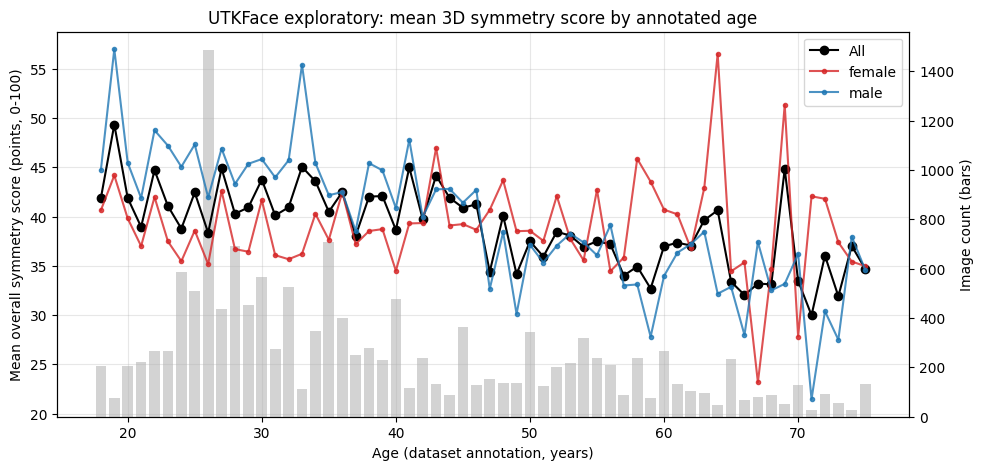

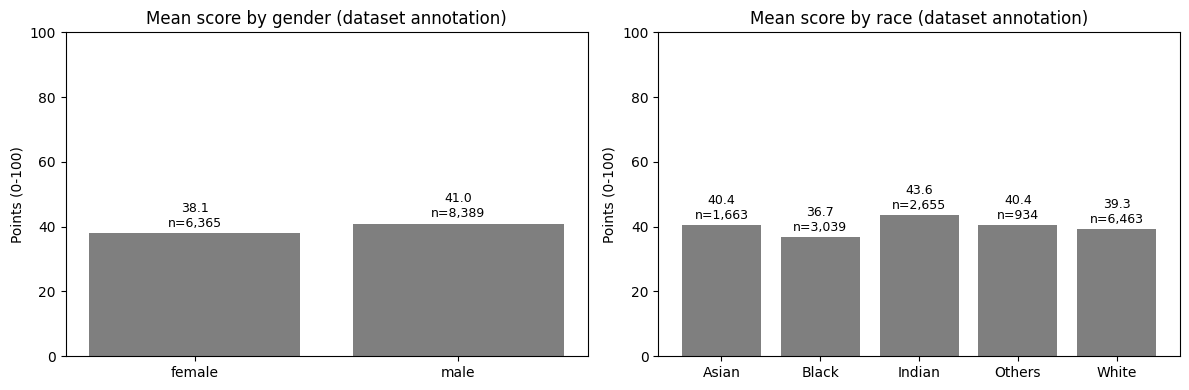

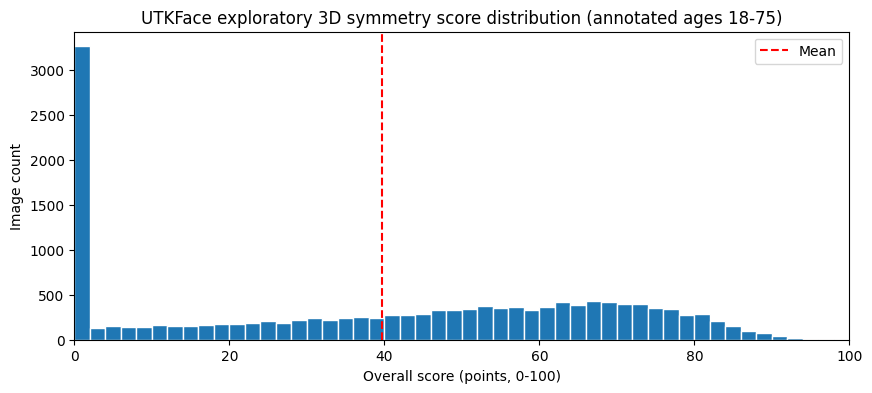

UTKFaceと固定した選別条件に限定した記述統計であり、探索値である。年齢・性別・人種ごとの平均は、対称度との相関・因果・優劣・人物の価値を示すものではない。群間の差はデータセットの撮影条件・注釈・構成比や、ランドマーク検出の群ごとの挙動差を含みうる。正常値・目標値・個人評価・人物間比較には使用できない。

個票 CSV      : /content/utkface_symmetry3d_records.csv
群平均 CSV    : /content/utkface_symmetry3d_group_means.csv
測定統計 CSV  : /content/utkface_symmetry3d_measurement_stats.csv
サマリ JSON   : /content/utkface_symmetry3d_summary.json


In [7]:
import importlib.metadata
import json
import platform
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:      # notebook 外で実行したとき
    display = print

OUTPUT_DIR = Path("/content")
RECORDS_CSV = OUTPUT_DIR / "utkface_symmetry3d_records.csv"
GROUP_CSV = OUTPUT_DIR / "utkface_symmetry3d_group_means.csv"
MEASUREMENT_CSV = OUTPUT_DIR / "utkface_symmetry3d_measurement_stats.csv"
SUMMARY_JSON = OUTPUT_DIR / "utkface_symmetry3d_summary.json"

SERIES = fsl_symmetry.SERIES                 # ("contour","eyes","nose","mouth","overall")
PART_NAMES = fsl_symmetry.PART_NAMES
AGE_BANDS = ((18, 24), (25, 34), (35, 44), (45, 54), (55, 64), (65, 75))
GROUP_DIMENSIONS = ("age", "age_band", "gender", "race")
DIMENSION_LABELS = {
    "age": "年齢（1歳きざみ・データセット注釈）",
    "age_band": "年齢帯（データセット注釈）",
    "gender": "性別（データセット注釈）",
    "race": "人種（データセット注釈のカテゴリ）",
}


def _age_band(age: int) -> str:
    for low, high in AGE_BANDS:
        if low <= age <= high:
            return f"{low}-{high}"
    raise ValueError(f"age band undefined: {age}")


# ---------- 1) 個票（画像は含まない）をファイルへ ----------
frame = pd.DataFrame.from_records(records).sort_values("image_id").reset_index(drop=True)
frame["age_band"] = [_age_band(int(age)) for age in frame["age"]]
frame.to_csv(RECORDS_CSV, index=False, encoding="utf-8")
print(f"個票 {len(frame):,} 行を書き出しました: {RECORDS_CSV}")
display(frame.head())


# ---------- 2) 集計の道具 ----------
def bootstrap_mean_ci95(values, *, samples, seed):
    array = np.asarray(values, dtype=np.float64)
    generator = np.random.default_rng(seed)
    means = np.empty(samples, dtype=np.float64)
    for start in range(0, samples, 100):
        count = min(100, samples - start)
        indices = generator.integers(0, len(array), size=(count, len(array)))
        means[start : start + count] = np.mean(array[indices], axis=1)
    low, high = np.quantile(means, [0.025, 0.975])
    return float(low), float(high)


def summarize(values, seed):
    array = np.asarray(values, dtype=np.float64)
    q1, median, q3 = np.quantile(array, [0.25, 0.5, 0.75])
    low, high = bootstrap_mean_ci95(array, samples=BOOTSTRAP_SAMPLES, seed=seed)
    return {
        "count": int(len(array)),
        "mean": float(np.mean(array)),
        "mean_ci95_low": low,
        "mean_ci95_high": high,
        "standard_deviation": float(np.std(array, ddof=1)) if len(array) > 1 else 0.0,
        "minimum": float(np.min(array)),
        "q1": float(q1),
        "median": float(median),
        "q3": float(q3),
        "maximum": float(np.max(array)),
    }


def group_summary(subset, seed):
    """1 グループ分の平均。標本が小さいときは CI を出さない（NaN を出さない）。"""
    points = subset["score_points"].to_numpy(dtype=np.float64)
    count = int(points.size)
    entry = {
        "count": count,
        "mean_score_points": float(points.mean()),
        "standard_deviation": float(points.std(ddof=1)) if count > 1 else 0.0,
        "median_score_points": float(np.median(points)),
        "mean_ci95_low": None,
        "mean_ci95_high": None,
        "mean_s3d_distance": float(subset["s3d_distance"].mean()),
    }
    if count >= MIN_GROUP_FOR_CI:
        entry["mean_ci95_low"], entry["mean_ci95_high"] = bootstrap_mean_ci95(
            points, samples=BOOTSTRAP_SAMPLES, seed=seed
        )
    for name in SERIES:
        entry[f"mean_symmetry_percent_{name}"] = float(
            subset[f"symmetry_percent_{name}"].mean()
        )
    return entry


# ---------- 3) 全体の統計 ----------
statistics = {}
for offset, name in enumerate(SERIES):
    statistics[f"distance_{name}"] = summarize(
        frame[f"distance_{name}"], RANDOM_SEED + offset
    )
    statistics[f"symmetry_percent_{name}"] = summarize(
        frame[f"symmetry_percent_{name}"], RANDOM_SEED + offset + 10
    )
statistics["distance_s3d_equal_weight"] = summarize(frame["s3d_distance"], RANDOM_SEED + 20)
statistics["overall_score_points"] = summarize(frame["score_points"], RANDOM_SEED + 30)

measurement_table = pd.DataFrame(statistics).T.rename_axis("measurement").reset_index()
measurement_table.to_csv(MEASUREMENT_CSV, index=False, encoding="utf-8")


# ---------- 4) 年齢・性別・人種それぞれの平均 ----------
group_rows = []
group_means = {}
for dimension_index, dimension in enumerate(GROUP_DIMENSIONS):
    per_group = {}
    for group_index, (label, subset) in enumerate(frame.groupby(dimension, sort=True)):
        entry = group_summary(
            subset, RANDOM_SEED + 1_000 * (dimension_index + 1) + group_index
        )
        per_group[str(label)] = entry
        group_rows.append({"dimension": dimension, "group": str(label), **entry})
    group_means[dimension] = per_group

group_table = pd.DataFrame(group_rows)
group_table.to_csv(GROUP_CSV, index=False, encoding="utf-8")


# ---------- 5) 実行条件の記録 ----------
def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


report = {
    "schema_version": "utkface-symmetry-3d-labelled/3.0.0",
    "status": "exploratory_descriptive_statistics_not_a_norm_or_target",
    "generated_at": datetime.now(UTC).isoformat(),
    "dataset": {
        "name": "UTKFace",
        "variant": "Aligned & Cropped Faces",
        "official_page": UTKFACE_OFFICIAL_PAGE_URL,
        "download_mirror": DATASET_MIRROR_URL,
        "download_mirror_handle": DATASET_MIRROR_HANDLE,
        "license_scope": "non-commercial research only",
        "inventory_sha256_names_and_sizes": DATASET_INVENTORY_SHA256,
        "label_source": "filename annotation: age_gender_race_datetime.jpg",
        "gender_codes": fsl_symmetry.GENDER_LABELS,
        "race_codes": fsl_symmetry.RACE_LABELS,
        "label_caveat": (
            "年齢・性別・人種はUTKFaceが配布時に付けた注釈であり、"
            "本notebookは推定しない。注釈自体の誤りは検証していない。"
        ),
    },
    "protocol": {
        "minimum_age": MIN_AGE,
        "maximum_age": MAX_AGE,
        "age_gate": "データセット注釈の年齢が 18〜75 の画像だけを測定する",
        "max_abs_yaw_deg": MAX_ABS_YAW_DEG,
        "max_abs_pitch_deg": MAX_ABS_PITCH_DEG,
        "max_abs_roll_deg": MAX_ABS_ROLL_DEG,
        "face_area_gate": "not applied to aligned/cropped images",
        "temporal_stability_gate": "not applicable to still images",
        "max_images": MAX_IMAGES,
        "random_seed": RANDOM_SEED,
        "bootstrap_samples": BOOTSTRAP_SAMPLES,
        "min_group_for_ci": MIN_GROUP_FOR_CI,
    },
    "counts": {
        "discovered_images": len(image_paths),
        "candidate_images": len(candidates),
        "selected_images": len(selected),
        "valid_images": valid_count,
        "valid_rate": valid_count / len(selected),
        "inventory_exclusions": dict(inventory_exclusions),
        "analysis_exclusions": dict(analysis_exclusions),
        "gender_totals": {
            str(key): int(value) for key, value in frame["gender"].value_counts().items()
        },
        "race_totals": {
            str(key): int(value) for key, value in frame["race"].value_counts().items()
        },
    },
    "reproducibility": {
        "implementation": "self-contained notebook (ported from symmetry-3d/1.0.0)",
        "metric_version": fsl_symmetry.METRIC_VERSION,
        "landmark_map_version": fsl_symmetry.LANDMARK_MAP_VERSION,
        "display_scale_version": fsl_symmetry.DISPLAY_SCALE_VERSION,
        "distance_at_full_score": fsl_symmetry.DISTANCE_AT_FULL_SCORE,
        "distance_at_zero_score": fsl_symmetry.DISTANCE_AT_ZERO_SCORE,
        "landmark_model_version": MODEL_VERSION,
        "landmark_model_sha256": sha256_file(MODEL_PATH),
        "landmark_delegate": "CPU",
        "demographic_model": "not used (labels come from the dataset filenames)",
        "python": platform.python_version(),
        "packages": {
            name: package_version(name)
            for name in ("mediapipe", "numpy", "pandas", "pillow",
                         "opencv-contrib-python", "kagglehub", "uv")
        },
    },
    "statistics": statistics,
    "group_means_overall_score_points": group_means,
    "outputs": {
        "per_image_records_csv": str(RECORDS_CSV),
        "group_means_csv": str(GROUP_CSV),
        "measurement_stats_csv": str(MEASUREMENT_CSV),
        "summary_json": str(SUMMARY_JSON),
    },
    "privacy": {
        "contains_images": False,
        "contains_landmarks": False,
        "contains_per_image_scores": True,
        "contains_filenames": True,
        "contains_age_gender_race_labels": True,
        "note": (
            "個票は後続分析のために保存する。画像・ランドマーク座標は保存しない。"
            "ファイル名はUTKFaceが配布する注釈そのものであり、個人識別情報ではない。"
        ),
    },
    "warning": (
        "UTKFaceと固定した選別条件に限定した記述統計であり、探索値である。"
        "年齢・性別・人種ごとの平均は、対称度との相関・因果・優劣・人物の価値を"
        "示すものではない。群間の差はデータセットの撮影条件・注釈・構成比や、"
        "ランドマーク検出の群ごとの挙動差を含みうる。"
        "正常値・目標値・個人評価・人物間比較には使用できない。"
    ),
}
SUMMARY_JSON.write_text(
    json.dumps(report, ensure_ascii=False, allow_nan=False, indent=2) + "\n",
    encoding="utf-8",
)


# ---------- 6) 表示 ----------
points_stats = statistics["overall_score_points"]
percent_stats = statistics["symmetry_percent_overall"]
part_labels = {"contour": "輪郭", "eyes": "目", "nose": "鼻", "mouth": "口"}

print("\n=== 全体平均（UTKFace 探索値・目標値ではない）===")
print(
    f"■ 全体のスコア : {points_stats['mean']:.2f} 点 / 100 "
    f"(95%CI {points_stats['mean_ci95_low']:.2f}–{points_stats['mean_ci95_high']:.2f})"
)
print(
    f"■ 全体の対称度 : {percent_stats['mean']:.2f} % "
    f"(95%CI {percent_stats['mean_ci95_low']:.2f}–{percent_stats['mean_ci95_high']:.2f})"
)
for name in PART_NAMES:
    print(f"   {part_labels[name]}の対称度: {statistics[f'symmetry_percent_{name}']['mean']:.2f} %")
print(f"採用: {valid_count:,}/{len(selected):,} ({valid_count / len(selected):.1%})")

display_columns = [
    "group", "count", "mean_score_points", "standard_deviation", "median_score_points",
    "mean_ci95_low", "mean_ci95_high", "mean_symmetry_percent_overall", "mean_s3d_distance",
]
for dimension in GROUP_DIMENSIONS:
    view = group_table.loc[group_table["dimension"] == dimension, display_columns]
    print(f"\n=== {DIMENSION_LABELS[dimension]} ごとの平均（全体のスコア: 点/100）===")
    display(view.reset_index(drop=True).round(3))


# ---------- 7) 図 ----------
age_rows = group_table[group_table["dimension"] == "age"].copy()
age_rows["age"] = age_rows["group"].astype(int)
age_rows = age_rows.sort_values("age")

figure, axis = plt.subplots(figsize=(11, 5))
counts_axis = axis.twinx()
counts_axis.bar(age_rows["age"], age_rows["count"], color="lightgray", width=0.8, zorder=1)
counts_axis.set_ylabel("Image count (bars)")
axis.plot(age_rows["age"], age_rows["mean_score_points"], marker="o",
          color="black", label="All", zorder=3)
for gender, colour in (("female", "tab:red"), ("male", "tab:blue")):
    subset = frame[frame["gender"] == gender].groupby("age")["score_points"].mean()
    axis.plot(subset.index, subset.to_numpy(), marker=".", color=colour, alpha=0.8,
              label=gender, zorder=3)
axis.set_zorder(counts_axis.get_zorder() + 1)
axis.patch.set_visible(False)
axis.set_xlabel("Age (dataset annotation, years)")
axis.set_ylabel("Mean overall symmetry score (points, 0-100)")
axis.set_title("UTKFace exploratory: mean 3D symmetry score by annotated age")
axis.grid(True, alpha=0.3)
axis.legend(loc="upper right")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, dimension in zip(axes, ("gender", "race")):
    rows = group_table[group_table["dimension"] == dimension]
    axis.bar(rows["group"], rows["mean_score_points"], color="tab:gray")
    axis.set_title(f"Mean score by {dimension} (dataset annotation)")
    axis.set_ylabel("Points (0-100)")
    axis.set_ylim(0, 100)
    for x, (mean, count) in enumerate(zip(rows["mean_score_points"], rows["count"])):
        axis.text(x, mean + 2, f"{mean:.1f}\nn={count:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(frame["score_points"], bins=np.arange(0, 101, 2), edgecolor="white")
plt.axvline(points_stats["mean"], color="red", linestyle="--", label="Mean")
plt.xlabel("Overall score (points, 0-100)")
plt.ylabel("Image count")
plt.title("UTKFace exploratory 3D symmetry score distribution (annotated ages 18-75)")
plt.xlim(0, 100)
plt.legend()
plt.show()

print(report["warning"])
print(f"\n個票 CSV      : {RECORDS_CSV}")
print(f"群平均 CSV    : {GROUP_CSV}")
print(f"測定統計 CSV  : {MEASUREMENT_CSV}")
print(f"サマリ JSON   : {SUMMARY_JSON}")

DOWNLOAD_REPORTS = False
if DOWNLOAD_REPORTS:
    from google.colab import files
    for path in (RECORDS_CSV, GROUP_CSV, MEASUREMENT_CSV, SUMMARY_JSON):
        files.download(str(path))